# SBHCloud (10 levels, no cooling, n384)

In [3]:
using Plots, Printf, Measures
using LaTeXStrings
include("../../../Utils/misc_stdout.jl")

Main.MiscStdout

## Strong Scaling

In [ ]:
let patt_dirss = [
        #([
        #    (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool"),
        #], "../data/BBHCloud_8lvl_nocool/n256/strong/", :cross),
        ([
            (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool-bigbox"),
        ], "../data/BBHCloud_8lvl_nocool/n256/strong-bigbox/", :x),
    ]

    xs = [1, 2, 4, 8, 16]

    # Plot Zcs/sec (left y-axis)
    plt = plot(
        title=L"\mathrm{Strong\,\,Scaling}",
        ylabel=L"\mathrm{zone-cycles\,\,s^{-1}}\,\,[10^8]",
        xlabel=L"\mathrm{Frontier\,\,Nodes}",
        xscale=:log10, yscale=:log10,
        legend=:bottomright,
        foreground_color_legend=nothing,
        background_color_legend=:white,
        legendfontsize=10,
        grid=true,
        gridalpha=0.3,
        minorgrid=false,
        size=(500,500)
    )
    xticks!(plt, xs, [string(n) for n in xs])
    ys = [1e8, 1e9, 1e10]
    yticks!(plt, ys, [L"10^{0}", L"10^{1}", L"10^{2}"])

    println("Zcs/sec:")
    for (patterns, parent_dir, mark) in patt_dirss
        # Load averages for the given patterns and directory
        dats, labs = MiscStdout.load_avgs(patterns, parent_dir; option = "ZcsPerSecond", range=:)
        # Iterate through the loaded datasets
        for (i, dat) in enumerate(dats)
            # Plot Zcs/sec (actual)
            plot!(plt, dat[1], dat[2], label=L"\mathrm{256^3\,\,Points\,\,8\,\,lvl}",
                  marker=:utriangle, markersize=8, markerstrokewidth=0, color=:black, linewidth=1.5)
            # Plot Ideal scaling
            plot!(plt, dat[1], dat[2][1] .* dat[1], label=L"\mathrm{Ideal}",
                  linestyle=:dash, color=:gray, marker=:utriangle, markersize=8,
                  markerstrokewidth=0, linewidth=1.5)

            @printf("  %8s: [", labs[i])
            println(join([@sprintf(" %8.2e", d) for d in dat[2]], ","), "]")

            # Plot Efficiency (right y-axis)
            value_per_node = dat[2] ./ dat[1]
            efficiency = value_per_node ./ first(value_per_node)
            plt2 = twinx()
            ylims!(plt2, (0, 1.1))
            # Ideal efficiency line (dashed, light red)
            plot!(plt2, dat[1], ones(length(dat[1])), label="",
                  linestyle=:dash, color=RGBA(1.0, 0.4, 0.4, 0.7),
                  marker=:utriangle, markersize=8, markerstrokewidth=0, linewidth=1.5)
            # Actual efficiency (solid red)
            plot!(plt2, dat[1], efficiency, label="",
                  marker=:utriangle, markersize=8, markerstrokewidth=0, color=:red, linewidth=1.5,
                  ylabel=L"\mathrm{Efficiency}", xscale=:log10, xticks=:none,
                  yguidefontcolor=:red, ytickfontcolor=:red, yforeground_color_axis=:red)
        end
    end

    display(plt)
    #savefig(plt, "BBHCloud-8lvl-nocool-strong-scaling.pdf")
end

## Weak Scaling

Vista zone-cycles/s: 1.71e+07, 1.32e+08, 4.39e+08, 1.02e+09
Vista efficiency: [1.0, 0.9676632359656921, 0.9499635579940106, 0.9347290160403846]
Horizon zone-cycles/s: 3.15e+08, 2.29e+09, 9.20e+09
Horizon efficiency: [1.0, 0.9094000957551637, 0.9135295724817335]


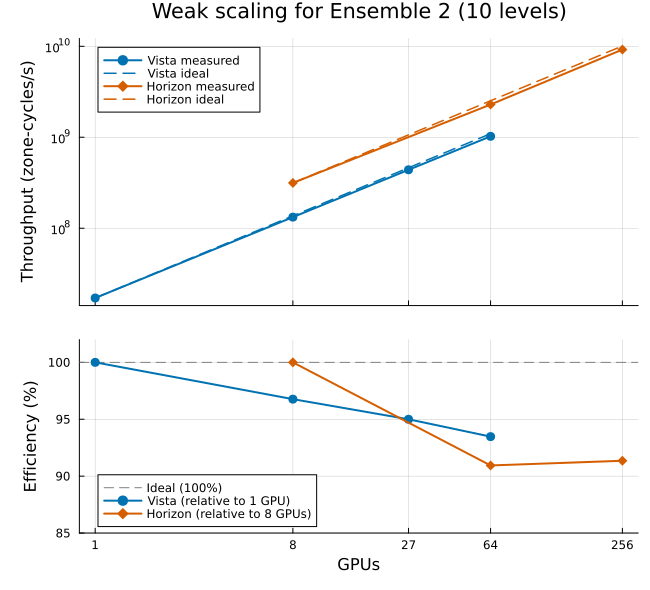

In [4]:
let machines = [
        (name="Vista", dir="../../../vista/2026May/data/SBHCloud_10lvl_nocool/n384/weak/",
         gpus_per_node=1, color="#0072B2", marker=:circle),
        (name="Horizon", dir="../data/SBHCloud_10lvl_nocool/n384/weak/",
         gpus_per_node=4, color="#D55E00", marker=:diamond),
    ]
    gpu_ticks = Int[]
    rate_plot = plot(
        title="Weak scaling for Ensemble 2 (10 levels)",
        ylabel="Throughput (zone-cycles/s)", yscale=:log10,
        yticks=10.0 .^ (7:10), xscale=:log10,
        legend=:topleft,
    )
    efficiency_plot = plot(
        ylabel="Efficiency (%)", xlabel="GPUs", xscale=:log10,
        ylims=(85, 102), yticks=85:5:100, legend=:bottomleft,
    )
    hline!(efficiency_plot, [100], color=:gray, linestyle=:dash, label="Ideal (100%)")

    for machine in machines
        patterns = [(r"SBHCloud_8lvl_nocool_N\d+_r0000", machine.name)]
        dats, _ = MiscStdout.load_avgs(patterns, machine.dir; option="ZcsPerSecond")
        nodes, throughput = only(dats)
        gpus = machine.gpus_per_node .* Int.(nodes)
        append!(gpu_ticks, gpus)
        baseline = first(gpus)
        ideal = first(throughput) .* (gpus ./ baseline)
        efficiency = throughput ./ ideal

        plot!(rate_plot, gpus, throughput, label=machine.name * " measured",
              color=machine.color, marker=machine.marker, linewidth=2,
              markersize=5, markerstrokewidth=0)
        plot!(rate_plot, gpus, ideal, label=machine.name * " ideal",
              color=machine.color, linestyle=:dash, linewidth=1.5)
        baseline_unit = baseline == 1 ? "GPU" : "GPUs"
        plot!(efficiency_plot, gpus, 100 .* efficiency,
              label="$(machine.name) (relative to $baseline $baseline_unit)",
              color=machine.color, marker=machine.marker, linewidth=2,
              markersize=5, markerstrokewidth=0)

        println(machine.name, " zone-cycles/s: ", join([@sprintf("%.2e", v) for v in throughput], ", "))
        println(machine.name, " efficiency: ", efficiency)
    end

    sort!(unique!(gpu_ticks))
    xticks!(rate_plot, gpu_ticks, fill("", length(gpu_ticks)))
    xticks!(efficiency_plot, gpu_ticks, string.(gpu_ticks))
    plt = plot(rate_plot, efficiency_plot, layout=grid(2, 1, heights=[0.58, 0.42]),
               link=:x, size=(650, 590), gridalpha=0.2, left_margin=4mm)
    display(plt)
    #savefig(plt, "SBHCloud-10lvl-nocool-weak-scaling.pdf")
end

## Speed

In [ ]:
let patt_dirss = [
        ([
            (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool-strong"),
        ], "../data/BBHCloud_8lvl_nocool/n256/strong/", :cross),
        ([
            (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool-weak"),
        ], "../data/BBHCloud_8lvl_nocool/n256/weak/", :circle),
    ]

    plts = []
    for (patterns, parent_dir, mark) in patt_dirss
        (vals, titles) = MiscStdout.load_values(patterns, parent_dir; option="TotalComputeTime")
        for (j, val) in enumerate(vals)
            (dats, labs) = val
            plt = plot(title=titles[j])
            for (i, dat) in enumerate(dats)
                plot!(plt, dat[1], dat[4], label=labs[i], marker=mark)
            end
            push!(plts, plt)
        end
    end

    plt = plot(plts..., layout=(length(plts), 1), size=(600, 300 * length(plts)))
    display(plt)
end